<a href="https://colab.research.google.com/github/kvikaee/data-analysis-python/blob/main/3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Кошурина Виктория Евгеньвена

412977

PYАД 1.5

# Домашнее задание по библиотеке Pandas

## 📝 Описание данных


**Таблица Pays** (файл pays.csv) содержит данные о платежах между компаниями:

| **Название признака**         | **Описание** |
|------------------|-------------|
| *hash_inn_kt*   | Обезличенный ИНН отправителя |
| *hash_inn_dt*   | Обезличенный ИНН получателя |
| *week*          | Неделя |
| *count*         | Кол-во платежей в неделю |
| *sum*           | Сумма платежей в неделю (обезличенная) |


**Таблица inn_info_public** (файл inn_info_public.csv) содержит характеристики отдельных компаний:  

| **Название признака**         | **Описание** |
|------------------|-------------|
| *hash_inn*      | Обезличенный ИНН |
| *okved2*        | Обезличенная отрасль (ОКВЭД)|
| *region*        | Обезличенный регион |
| *is_public*     | Флаг публичной компании (True, если да) |

## 💫 Приступаем к работе

Теперь можно начинать! Импорт библиотеки pandas уже записан, для выполнения заданий достаточно только её, ~но если Вам захочется импортировать что-то ещё - это не возбраняется:)~.

Далее прочитайте файл удобным способом и выполняйте задания по порядку, код можно писать непосредственно сразу после условия задач, в отведённых под это ячейках.

*Совет (особенно для последних заданий): первым делом вдумайтесь в условие и прикиньте схему решения - какие таблицы Вам понадобятся, нужно ли что-то сгруппировать/объединить, по каким полям и с какими агрегирующими функциями... И только после этого приступайте к реализации задуманного на Python.*



In [ ]:
import pandas as pd

In [ ]:
pays_data = pd.read_csv('pays.csv')
inn_info_public = pd.read_csv('inn_info_public.csv')

### Задание 1

Выведите размерность (количество строк и столбцов) и первые 3 строки для каждой таблицы.

In [ ]:
print("pays")
print(f"Размерность: {pays_data.shape[0]} строк, {pays_data.shape[1]} столбцов")
print(pays_data.head(3))
print("\n")

print("inn_info_public")
print(f"Размерность: {inn_info_public.shape[0]} строк, {inn_info_public.shape[1]} столбцов")
print(inn_info_public.head(3))

pays
Размерность: 872344 строк, 5 столбцов
   hash_inn_kt  hash_inn_dt  week  count      sum
0            0            0   1.0    4.0  38399.6
1            0            0   5.0    2.0    399.6
2            0            0   7.0    2.0     79.6


inn_info_public
Размерность: 240069 строк, 4 столбцов
   hash_inn  okved2  region  is_public
0     61058      34      86       True
1      8311      18      86       True
2    130273      -1      86      False


### Задание 2
Посчитайте количество пропусков в каждой таблице по столбцам.

In [ ]:
print("pays")
print(pays_data.isnull().sum().to_string())
print("\n")

print("inn_info_public")
print(inn_info_public.isnull().sum().to_string())

pays
hash_inn_kt      0
hash_inn_dt      0
week             1
count            1
sum            160


inn_info_public
hash_inn     0
okved2       0
region       0
is_public    0


### Задание 3
Определите количество уникальных компаний в таблице **pays** (как отправителей, так и получателей).

In [ ]:
unique_senders = pays_data['hash_inn_kt'].nunique()
unique_receivers = pays_data['hash_inn_dt'].nunique()
unique_total = set(pays_data['hash_inn_kt'].unique()) | set(pays_data['hash_inn_dt'].unique())

print(f"Уникальные отправители (hash_inn_kt): {unique_senders}")
print(f"Уникальные получатели (hash_inn_dt): {unique_receivers}")
print(f"Всего уникальных компаний: {len(unique_total)}")

Уникальные отправители (hash_inn_kt): 23075
Уникальные получатели (hash_inn_dt): 77484
Всего уникальных компаний: 91815


### Задание 4

Найдите сумму и среднее количество платежей по неделям.

In [ ]:
weekly_stats = pays_data.groupby('week')[['count', 'sum']].agg({
    'count': ['sum', 'mean'],
    'sum': ['sum', 'mean']
})

print("Статистика по неделям:")
print(weekly_stats.applymap(lambda x: f"{x:.2f}"))

Статистика по неделям:
           count                sum        
             sum  mean          sum    mean
week                                       
0.00     1477.00  3.61     72584.13  177.47
1.00   110622.00  2.90  13378765.04  350.90
2.00   110371.00  2.91  12196160.27  321.62
3.00   111927.00  2.91  11856223.50  308.64
4.00   112833.00  2.87  12150001.78  309.33
5.00   111184.00  2.89  12019695.39  312.23
6.00   112533.00  2.95  11426458.34  299.35
7.00    74938.00  2.70   9088911.64  327.09
8.00   131278.00  2.96  16091184.40  362.87
9.00    99464.00  2.78  10940667.53  305.61
10.00  125367.00  2.95  14078174.28  330.96
11.00  125913.00  2.96  13159273.70  309.40
12.00  124892.00  2.95  14667948.38  346.44
13.00  123878.00  2.90  12725455.51  298.04
14.00  122210.00  2.91  12612980.17  300.83
15.00  123060.00  2.97  13436509.99  324.40
16.00  127822.00  2.99  14875678.63  348.35
17.00  104706.00  2.84  11012575.52  298.81
18.00   86007.00  2.74   9654137.11  307.77
19.00  12

/tmp/ipython-input-830372844.py:7: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  print(weekly_stats.applymap(lambda x: f"{x:.2f}"))


### Задание 5

Определите 5 компаний (по `hash_inn_kt`), которые отправили наибольшую сумму платежей за весь период.

In [ ]:
top_5_senders = pays_data.groupby('hash_inn_kt')['sum'].sum().nlargest(5)

print("ТОП-5 компаний (отправители) с наибольшей суммой платежей:")
for idx, (hash_inn, total_sum) in enumerate(top_5_senders.items(), 1):
    print(f"{idx}. hash_inn_kt: {hash_inn}, сумма: {total_sum}")

ТОП-5 компаний (отправители) с наибольшей суммой платежей:
1. hash_inn_kt: 3695, сумма: 8979453.992
2. hash_inn_kt: 21684, сумма: 6946891.356
3. hash_inn_kt: 19855, сумма: 6144644.944
4. hash_inn_kt: 3820, сумма: 5153848.5
5. hash_inn_kt: 26044, сумма: 4579517.632


### Задание 6

По данным таблицы **inn_info_public** исследуйте распределение ОКВЭДов (подсчитайте для каждого типа ОКВЭДа сколько компаний из таблицы к нему относятся). Визуализируйте распределение *(поможет метод `hist`)*.

In [ ]:
okved_distribution = inn_info_public['okved2'].value_counts().sort_index()

okved_table = pd.DataFrame({
    'ОКВЕДУ': okved_distribution.index,
    'Количество компаний': okved_distribution.values
})

pd.set_option('display.max_rows', None)
print(okved_table.to_string(index=False))


 ОКВЕДУ  Количество компаний
     -1                78654
      0                  815
      1                   50
      2                   90
      3                  842
      4                 7617
      5                  250
      6                 2456
      7                  649
      8                 4658
      9                 1887
     10                 1006
     11                 2850
     12                44918
     13                   68
     14                10179
     15                  436
     16                 1873
     17                  241
     18                 1999
     19                  560
     20                  851
     21                 1254
     22                 1385
     23                  556
     24                  388
     25                  203
     26                 3141
     27                  280
     28                  253
     29                 1905
     30                 1297
     31                  166
     32       

In [ ]:
import matplotlib.pyplot as plt

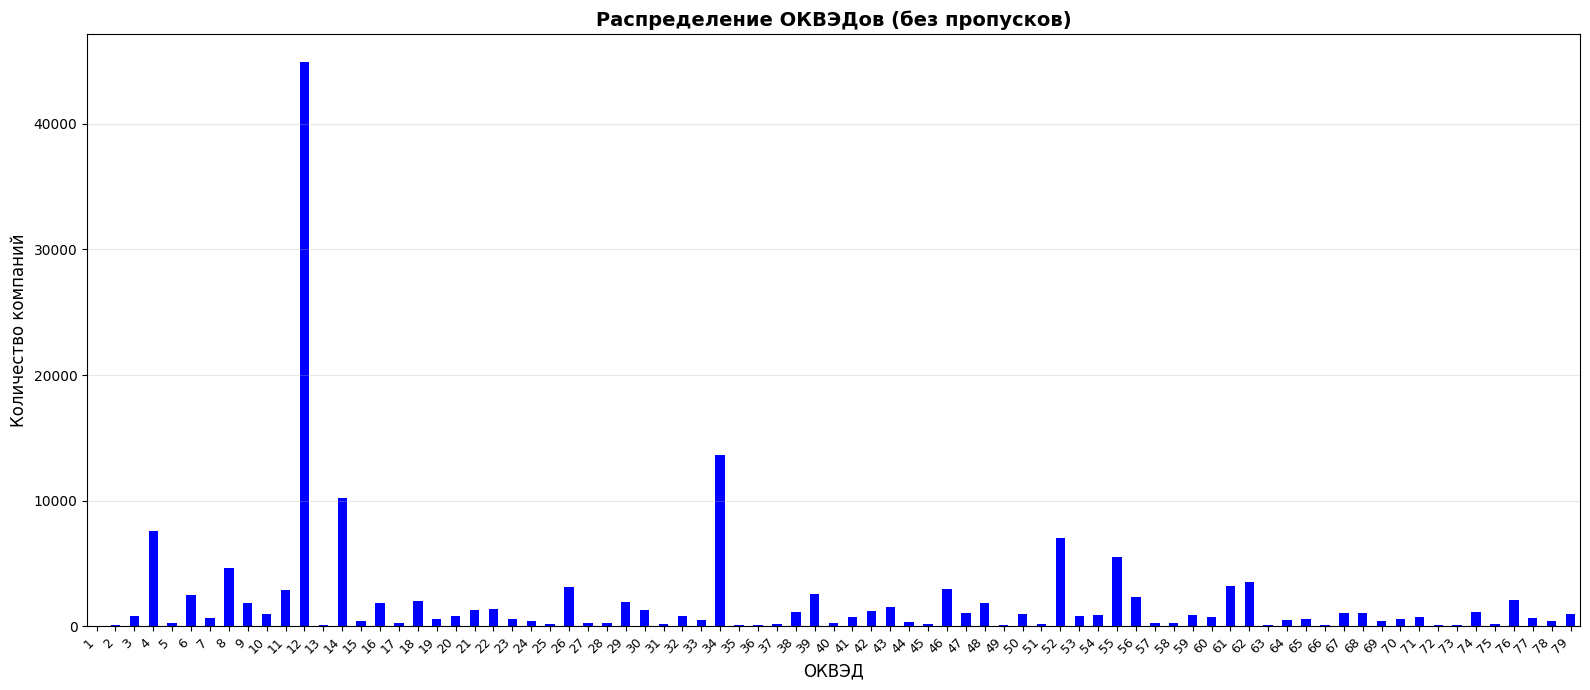

In [ ]:
okved_clean = inn_info_public[(inn_info_public['okved2'] > 0)]['okved2'].value_counts() #убираем 0 и -1 из оквэда

okved_sorted = okved_clean.sort_index()

plt.figure(figsize=(16, 7))
okved_sorted.plot(kind='bar', color='blue', linewidth=0.5)
plt.title('Распределение ОКВЭДов (без пропусков)', fontsize=14, fontweight='bold')
plt.xlabel('ОКВЭД', fontsize=12)
plt.ylabel('Количество компаний', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Задание 7

Добавьте в таблицу Pays информацию об ОКВЭДе и регионе отправителя (`hash_inn_kt`) и получателя (`hash_inn_dt`).

*Подсказка: здесь нужно поработать с двумя таблицами одновременно*

In [ ]:
pays_enriched = pays_data.copy()

# данные отправителя
sender_info = inn_info_public[['hash_inn', 'okved2', 'region']].rename(columns={
    'okved2': 'okved2_sender',
    'region': 'region_sender'
})
pays_enriched = pays_enriched.merge(sender_info, left_on='hash_inn_kt', right_on='hash_inn', how='left')
pays_enriched = pays_enriched.drop('hash_inn', axis=1)

# данные получателя
receiver_info = inn_info_public[['hash_inn', 'okved2', 'region']].rename(columns={
    'okved2': 'okved2_receiver',
    'region': 'region_receiver'
})
pays_enriched = pays_enriched.merge(receiver_info, left_on='hash_inn_dt', right_on='hash_inn', how='left')
pays_enriched = pays_enriched.drop('hash_inn', axis=1)

print(pays_enriched.head())


   hash_inn_kt  hash_inn_dt  week  count      sum  okved2_sender  \
0            0            0  1.00   4.00 38399.60             -1   
1            0            0  5.00   2.00   399.60             -1   
2            0            0  7.00   2.00    79.60             -1   
3            0            0  9.00   2.00   239.60             -1   
4            0            0 12.00   2.00    79.60             -1   

   region_sender  okved2_receiver  region_receiver  
0             84            -1.00            84.00  
1             84            -1.00            84.00  
2             84            -1.00            84.00  
3             84            -1.00            84.00  
4             84            -1.00            84.00  


### Задание 8


Используя результат, полученный в предыдущем задании, создайте таблицу, в которой для каждой отрасли (ОКВЭДа) указана сумма платежей, отправленных компаниями из этой отрасли.

In [ ]:
okved_sums = pays_enriched.groupby('okved2_sender')['sum'].sum().sort_values(ascending=False)

okved_table = pd.DataFrame({
    'ОКВЭД отправителя': okved_sums.index,
    'Сумма платежей': okved_sums.values,
    'Процент (%)': (okved_sums.values / okved_sums.sum() * 100).round(2)
})

print(okved_table.to_string(index=False))

 ОКВЭД отправителя  Сумма платежей  Процент (%)
                -1    101965343.23        36.34
                12     48748279.13        17.37
                39     18036776.00         6.43
                34      9554911.65         3.40
                 4      8941388.70         3.19
                26      8793643.26         3.13
                14      6005831.25         2.14
                76      5100705.39         1.82
                55      5011525.65         1.79
                52      4720481.91         1.68
                 8      4452465.85         1.59
                61      4270340.91         1.52
                46      4109724.89         1.46
                43      3678531.66         1.31
                68      3491504.54         1.24
                42      2690536.81         0.96
                22      2639487.74         0.94
                59      2315451.98         0.83
                74      2165565.20         0.77
                72      2125792.26      

### Задание 9
Определите, какую долю от общего объема составляют платежи, где отправитель и получатель находятся в разных регионах.

In [ ]:
# сумма всех платежей
total_sum = pays_enriched['sum'].sum()

# сумма платежей между разными регионами
different_regions = pays_enriched[pays_enriched['region_sender'] != pays_enriched['region_receiver']]['sum'].sum()

# доля в процентах
percent_different = (different_regions / total_sum * 100)

print(f"Общая сумма платежей: {total_sum:,.0f}")
print(f"Сумма платежей между разными регионами: {different_regions:,.0f}")
print(f"Доля платежей между разными регионами: {percent_different:.2f}%")

Общая сумма платежей: 280,616,853
Сумма платежей между разными регионами: 98,509,968
Доля платежей между разными регионами: 35.10%


### Задание 10
Определите среднюю сумму платежей для публичных (`is_public == 1`) и непубличных компаний (`is_public == 0`).

In [ ]:
# флаг публичности для отправителей
pays_with_public = pays_enriched.merge(
    inn_info_public[['hash_inn', 'is_public']],
    left_on='hash_inn_kt',
    right_on='hash_inn',
    how='left'
)
pays_with_public = pays_with_public.rename(columns={'is_public': 'is_public_sender'})
pays_with_public = pays_with_public.drop('hash_inn', axis=1)

# флаг публичности для получателей
pays_with_public = pays_with_public.merge(
    inn_info_public[['hash_inn', 'is_public']],
    left_on='hash_inn_dt',
    right_on='hash_inn',
    how='left'
)
pays_with_public = pays_with_public.rename(columns={'is_public': 'is_public_receiver'})
pays_with_public = pays_with_public.drop('hash_inn', axis=1)

# средняя сумма для публичных отправителей
avg_public_sender = pays_with_public[pays_with_public['is_public_sender'] == 1]['sum'].mean()
avg_private_sender = pays_with_public[pays_with_public['is_public_sender'] == 0]['sum'].mean()

print("ОТПРАВИТЕЛИ:")
print(f"Средняя сумма платежей (публичные компании): {avg_public_sender:,.2f}")
print(f"Средняя сумма платежей (непубличные компании): {avg_private_sender:,.2f}")
print()

# средняя сумма для публичных получателей
avg_public_receiver = pays_with_public[pays_with_public['is_public_receiver'] == 1]['sum'].mean()
avg_private_receiver = pays_with_public[pays_with_public['is_public_receiver'] == 0]['sum'].mean()

print("ПОЛУЧАТЕЛИ:")
print(f"Средняя сумма платежей (публичные компании): {avg_public_receiver:,.2f}")
print(f"Средняя сумма платежей (непубличные компании): {avg_private_receiver:,.2f}")


ОТПРАВИТЕЛИ:
Средняя сумма платежей (публичные компании): 301.19
Средняя сумма платежей (непубличные компании): 365.43

ПОЛУЧАТЕЛИ:
Средняя сумма платежей (публичные компании): 330.56
Средняя сумма платежей (непубличные компании): 303.24


### Задание * (по желанию и возможностям)

Если у Вас есть свои наблюдения, дополните анализ данных.

#  Внутрирегиональные vs межрегиональные платежи

In [ ]:
same_region = pays_enriched[pays_enriched['region_sender'] == pays_enriched['region_receiver']]['sum'].sum()
different_region = pays_enriched[pays_enriched['region_sender'] != pays_enriched['region_receiver']]['sum'].sum()
total = same_region + different_region

print(f"Внутрирегиональные платежи: {same_region:,.0f} ({same_region/total*100:.2f}%)")
print(f"Межрегиональные платежи: {different_region:,.0f} ({different_region/total*100:.2f}%)")


Внутрирегиональные платежи: 182,106,884 (64.90%)
Межрегиональные платежи: 98,509,968 (35.10%)


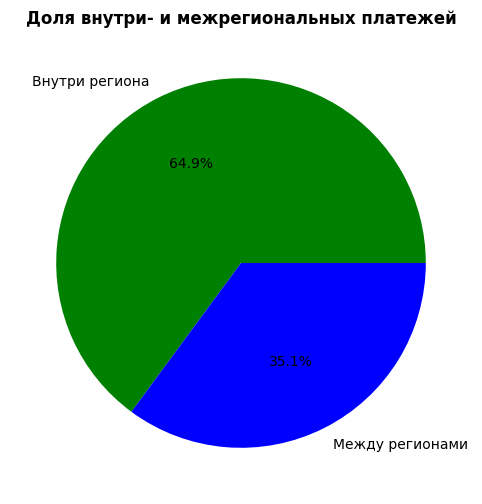

In [ ]:
plt.figure(figsize=(8, 6))
plt.pie([same_region, different_region],
        labels=['Внутри региона', 'Между регионами'],
        autopct='%1.1f%%',
        colors=['green', 'blue'])
plt.title('Доля внутри- и межрегиональных платежей', fontsize=12, fontweight='bold')
plt.show()

#  Топ регионов по объему платежей

In [ ]:
region_sums_sender = pays_enriched.groupby('region_sender')['sum'].sum().sort_values(ascending=False)

print("ТОП-10 регионов по объему платежей (отправители):")
print(region_sums_sender.head(10))
print()

ТОП-10 регионов по объему платежей (отправители):
region_sender
84   79155094.83
85   68769889.50
60   23500550.19
80   21959522.01
82   17286253.39
87   15371527.39
17   12213994.21
41    9318366.48
23    6100614.08
24    3713598.31
Name: sum, dtype: float64



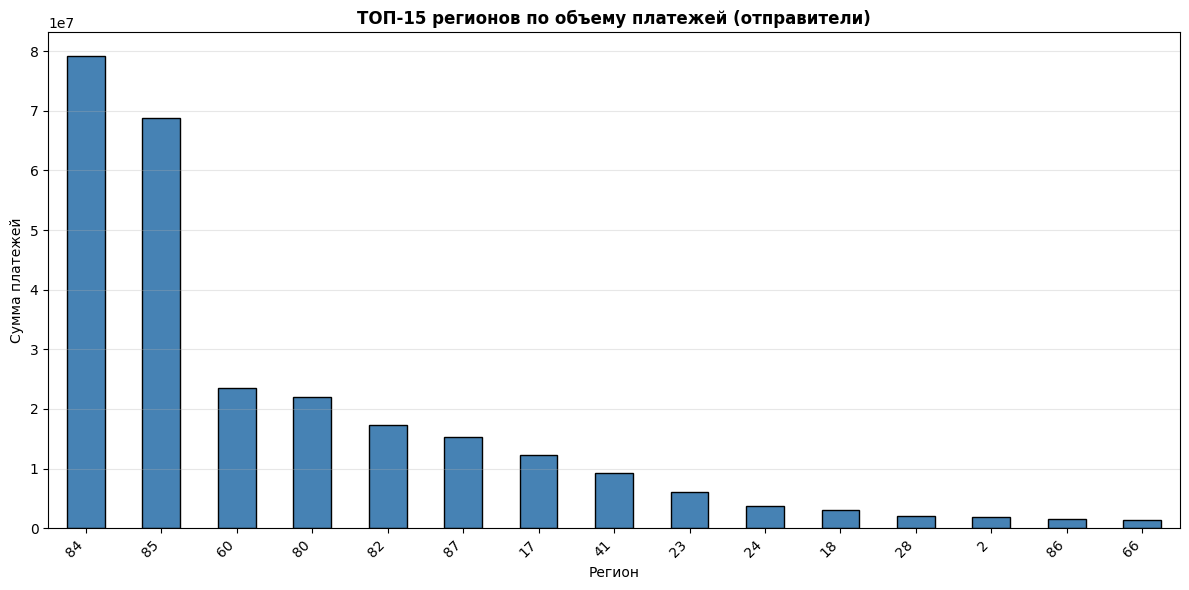

In [ ]:
plt.figure(figsize=(12, 6))
region_sums_sender.head(15).plot(kind='bar', color='steelblue', edgecolor='black')
plt.title('ТОП-15 регионов по объему платежей (отправители)', fontsize=12, fontweight='bold')
plt.xlabel('Регион', fontsize=10)
plt.ylabel('Сумма платежей', fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()